# Homework 04: Evaluation Metrics for Classification

**Course:** Machine Learning Zoomcamp (2026 Cohort)  
**Author:** Wisnu Anugrah Pratama  
**GitHub:** [@wapratama](https://github.com/wapratama)

---

### Overview
This notebook contains my solutions and technical write-up for **Homework 04: Evaluation Metrics for Classification** as part of the [Machine Learning Zoomcamp](https://github.com/DataTalksClub/machine-learning-zoomcamp) by DataTalksClub.

### **Download the Dataset**
Download the official **2026 Car Fuel Efficiency** dataset directly into your `data/` directory

In [1]:
!curl -o ../data/hw4_course_lead_scoring_2026.csv https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0   0     0   0     0     0     0  --:--:-- --:--:-- --:--:--     0
 11 278746  11 31816   0     0 58152     0   0:00:04 --:--:--  0:00:04 58377
100 278746 100 278746   0     0 410739     0  --:--:-- --:--:-- --:--:-- 412346


### Data preparation

* Check if the missing values are presented in the features.
* If there are missing values:
    * For categorical features, replace them with 'NA'
    * For numerical features, replace with with 0.0 

In [2]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv('../data/hw4_course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df.describe(include='all')

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
count,4852,4760,4806,4792,4631.000000,5000.000000,5000.000000,4965.000000,5000.000000
unique,5,6,4,5,NaN,NaN,NaN,NaN,NaN
top,organic_search,technology,employed,north_america,NaN,NaN,NaN,NaN,NaN
freq,1251,1173,2633,1371,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,54533.212049,2.089400,4.472600,0.494767,0.576600
std,NaN,NaN,NaN,NaN,21245.661710,1.188987,2.435906,0.199431,0.494147
min,NaN,NaN,NaN,NaN,12000.000000,0.000000,0.000000,0.010000,0.000000
25%,NaN,NaN,NaN,NaN,40458.500000,1.000000,3.000000,0.360000,0.000000
50%,NaN,NaN,NaN,NaN,55051.000000,2.000000,4.000000,0.490000,1.000000
75%,NaN,NaN,NaN,NaN,71252.500000,3.000000,6.000000,0.630000,1.000000


In [4]:
# Function to display information about missing value
def show_null(df):
    """
    Return the total missing values and the percentage of
    missing values by column.
    """
    null_count = df.isnull().sum()
    null_percentage = (null_count / df.shape[0]) * 100
    empty_count = pd.Series(((df == ' ') | (df == '')).sum())
    empty_percentage = (empty_count / df.shape[0]) * 100
    nan_count = pd.Series(((df == 'nan') | (df == 'NaN') | (df == np.nan)).sum())
    nan_percentage = (nan_count / df.shape[0]) * 100
    return pd.DataFrame({'num_missing': null_count,
                         'missing_percentage': null_percentage,
                         'num_empty': empty_count,
                         'empty_percentage': empty_percentage,
                         'nan_count': nan_count,
                         'nan_percentage': nan_percentage})

show_null(df)

,num_missing,missing_percentage,num_empty,empty_percentage,nan_count,nan_percentage
lead_source,148,2.96,0,0.0,0,0.0
industry,240,4.80,0,0.0,0,0.0
employment_status,194,3.88,0,0.0,0,0.0
location,208,4.16,0,0.0,0,0.0
annual_income,369,7.38,0,0.0,0,0.0
number_of_courses_viewed,0,0.00,0,0.0,0,0.0
interaction_count,0,0.00,0,0.0,0,0.0
lead_score,35,0.70,0,0.0,0,0.0
converted,0,0.00,0,0.0,0,0.0


In [5]:
# Classify Data
target = 'converted'
categorical = list(df.select_dtypes(include=['object']).columns)
numerical = list(df.select_dtypes(include=['int64', 'float64']).columns)

if target in numerical:
    numerical.remove(target)

# Impute missing values
for col in categorical:
    df[col] = df[col].fillna('NA')

for col in numerical:
    df[col] = df[col].fillna(0.0)

C:\Users\wisnuap\AppData\Local\Temp\ipykernel_12556\979642325.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = list(df.select_dtypes(include=['object']).columns)


In [6]:
# Check missing value after imputation
show_null(df)

,num_missing,missing_percentage,num_empty,empty_percentage,nan_count,nan_percentage
lead_source,0,0.0,0,0.0,0,0.0
industry,0,0.0,0,0.0,0,0.0
employment_status,0,0.0,0,0.0,0,0.0
location,0,0.0,0,0.0,0,0.0
annual_income,0,0.0,0,0.0,0,0.0
number_of_courses_viewed,0,0.0,0,0.0,0,0.0
interaction_count,0,0.0,0,0.0,0,0.0
lead_score,0,0.0,0,0.0,0,0.0
converted,0,0.0,0,0.0,0,0.0


In [7]:
# Split data (60% Train, 20% Val, 20% Test) with random_state=1
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

del df_train[target]
del df_val[target]
del df_test[target]

### Homework Solution

#### Question 1: ROC AUC feature importance
ROC AUC could also be used to evaluate feature importance of numerical variables. 

Let's do that

* For each numerical variable, use it as score (aka prediction) and compute the AUC with the `y` variable as ground truth.
* Use the training dataset for that


If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. `-df_train['balance']`)

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income`

In [9]:
from sklearn.metrics import roc_auc_score

for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    print(f"{col:26}: {auc:.4f}")

annual_income             : 0.6082
number_of_courses_viewed  : 0.7230
interaction_count         : 0.7649
lead_score                : 0.7882


#### Question 2: Training the model

Apply one-hot-encoding using `DictVectorizer` and train the logistic regression with these parameters:

```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

What's the AUC of this model on the validation dataset? (round to 3 digits)

In [10]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

train_dicts = df_train[categorical + numerical].to_dict(orient='records')
val_dicts = df_val[categorical + numerical].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred_val = model.predict_proba(X_val)[:, 1]
val_auc = roc_auc_score(y_val, y_pred_val)
print(f"Validation ROC AUC: {round(val_auc, 3)}")

Validation ROC AUC: 0.732


#### Question 3: Precision and Recall

Now let's compute precision and recall for our model.

* Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
* For each threshold, compute precision and recall
* Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at
which both metrics are zero, and choose the threshold with the smallest
absolute difference between precision and recall.

In [18]:
thresholds = np.linspace(0, 1, 101)
scores = []

for t in thresholds:
    predict_positive = (y_pred_val >= t)
    predict_negative = (y_pred_val < t)
    
    tp = (predict_positive & (y_val == 1)).sum()
    fp = (predict_positive & (y_val == 0)).sum()
    fn = (predict_negative & (y_val == 1)).sum()
    
    p = tp / (tp + fp) if (tp + fp) > 0 else 0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    scores.append((t, p, r))

df_scores = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall'])
df_scores['diff'] = (df_scores['precision'] - df_scores['recall']).abs()

In [19]:
df_scores

,threshold,precision,recall,diff
0,0.00,0.586,1.000000,0.414000
1,0.01,0.586,1.000000,0.414000
2,0.02,0.586,1.000000,0.414000
3,0.03,0.586,1.000000,0.414000
4,0.04,0.586,1.000000,0.414000
...,...,...,...,...
96,0.96,1.000,0.001706,0.998294
97,0.97,0.000,0.000000,0.000000
98,0.98,0.000,0.000000,0.000000
99,0.99,0.000,0.000000,0.000000


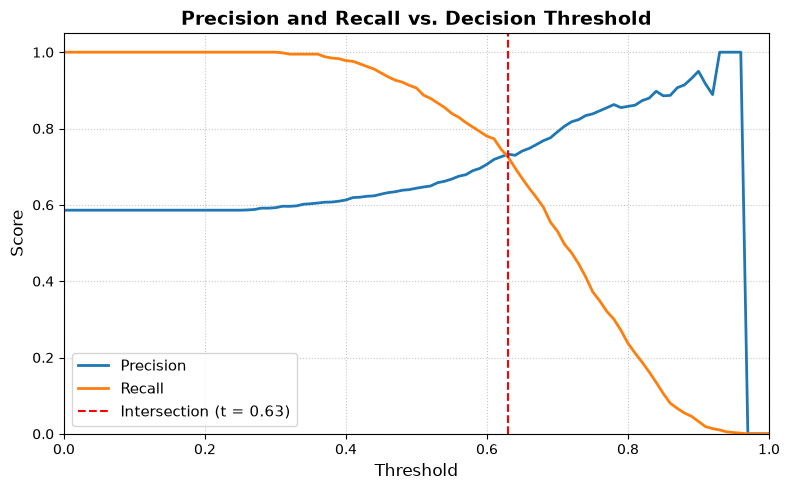

In [21]:
import matplotlib.pyplot as plt

# Set figure size
plt.figure(figsize=(8, 5))

# Plot Precision and Recall curves
plt.plot(df_scores['threshold'], df_scores['precision'], label='Precision', color='#1f77b4', linewidth=2)
plt.plot(df_scores['threshold'], df_scores['recall'], label='Recall', color='#ff7f0e', linewidth=2)

# Highlight the intersection threshold at 0.63
intersection_t = 0.63
plt.axvline(x=intersection_t, color='red', linestyle='--', linewidth=1.5, label=f'Intersection (t = {intersection_t})')

# Add labels, title, legend, and grid
plt.xlabel('Threshold', fontsize=12)
plt.ylabel('Score', fontsize=12)
plt.title('Precision and Recall vs. Decision Threshold', fontsize=14, fontweight='bold')
plt.xlim([0, 1])
plt.ylim([0, 1.05])
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=11, loc='lower left')

plt.tight_layout()
plt.show()

In [20]:
# Exclude points where metrics are zero
best_intersection = df_scores[(df_scores['precision'] > 0) & (df_scores['recall'] > 0)].sort_values('diff').iloc[0]
print(f"Intersection Threshold: {best_intersection['threshold']:.2f}")
print(f"Precision: {best_intersection['precision']:.3f}, Recall: {best_intersection['recall']:.3f}")

Intersection Threshold: 0.63
Precision: 0.733, Recall: 0.725


#### Question 4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

Where $P$ is precision and $R$ is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

- 0.21
- 0.41
- 0.61
- 0.81

In [22]:
df_scores['f1'] = 2 * df_scores['precision'] * df_scores['recall'] / (df_scores['precision'] + df_scores['recall'])
df_scores['f1'] = df_scores['f1'].fillna(0)

max_f1_row = df_scores.sort_values('f1', ascending=False).iloc[0]
print(f"Max F1 ({max_f1_row['f1']:.4f}) at Threshold: {max_f1_row['threshold']:.2f}")

Max F1 (0.7576) at Threshold: 0.41


### Question 5: 5-Fold CV


Use the `KFold` class from Scikit-Learn to evaluate our model on 5 different folds:

```
KFold(n_splits=5, shuffle=True, random_state=1)
```

* Iterate over different folds of `df_full_train`
* Split the data into train and validation
* Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
* Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

In [23]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores_cv = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_v = df_full_train.iloc[val_idx]
    
    y_tr = df_tr['converted'].values
    y_v = df_v['converted'].values
    
    dv_f = DictVectorizer(sparse=False)
    X_tr = dv_f.fit_transform(df_tr[categorical + numerical].to_dict(orient='records'))
    X_v = dv_f.transform(df_v[categorical + numerical].to_dict(orient='records'))
    
    m_f = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    m_f.fit(X_tr, y_tr)
    
    preds = m_f.predict_proba(X_v)[:, 1]
    auc = roc_auc_score(y_v, preds)
    scores_cv.append(auc)

std_score = np.std(scores_cv)
print(f"5-Fold CV AUC Scores: {[round(s, 4) for s in scores_cv]}")
print(f"Standard Deviation: {round(std_score, 3)}")

5-Fold CV AUC Scores: [0.7306, 0.7296, 0.7363, 0.7412, 0.7209]
Standard Deviation: 0.007


#### Question 6: Hyperparameter Tuning

Now let's use 5-Fold cross-validation to find the best parameter `C`

* Iterate over the following `C` values: `[0.000001, 0.001, 1]`
* Initialize `KFold` with the same parameters as previously
* Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
* Compute the mean ROC AUC as well as the std (round the mean and std to 3
  decimal digits).

Which `C` leads to the best mean ROC AUC?

- 0.000001
- 0.001
- 1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest `C`.

In [25]:
c_values = [0.000001, 0.001, 1]

for c in c_values:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores_c = []
    
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_v = df_full_train.iloc[val_idx]
        
        y_tr = df_tr['converted'].values
        y_v = df_v['converted'].values
        
        dv_f = DictVectorizer(sparse=False)
        X_tr = dv_f.fit_transform(df_tr[categorical + numerical].to_dict(orient='records'))
        X_v = dv_f.transform(df_v[categorical + numerical].to_dict(orient='records'))
        
        m_f = LogisticRegression(solver='liblinear', C=c, max_iter=1000)
        m_f.fit(X_tr, y_tr)
        
        preds = m_f.predict_proba(X_v)[:, 1]
        auc = roc_auc_score(y_v, preds)
        scores_c.append(auc)
        
    mean_auc = np.mean(scores_c)
    std_auc = np.std(scores_c)
    print(f"C = {c:>8}: Mean AUC = {round(mean_auc, 3)}, Std = {round(std_auc, 3)}")

C =    1e-06: Mean AUC = 0.617, Std = 0.019
C =    0.001: Mean AUC = 0.749, Std = 0.01
C =        1: Mean AUC = 0.732, Std = 0.007


The best choice is **0.001**, as it achieves the **highest Mean ROC AUC score of 0.749**.